# Bước 2 — Tích hợp & Làm sạch Dữ liệu (ETL)

**Đề tài:** Phân tích & dự báo giá thuê nhà trọ/căn hộ **theo khu vực** — *Nhập môn Khoa học Dữ liệu (IT4930)*

Notebook thực hiện **Bước 2** trong vòng đời Khai phá Tri thức (Slide L3):
*Extract → Transform → Load*. Khâu Thu thập+Xử lý chiếm **70–90%** công sức dự án
(John Dickerson, UMD) — đây chính là phần "Xử lý".

**Đầu vào (kết quả Bước 1):** `data/raw/full_data_combined.csv` — dữ liệu thô gộp từ
**11 nguồn web** đã cào.
**Đầu ra (sản phẩm Bước 2):** ba tập đã làm sạch trong `v2/data/processed/` —
trọng tâm là `rental_data_clean.csv` (đầu vào cho EDA Bước 3 & mô hình Bước 4).

> 🔒 **Lưu ý vận hành:** notebook ghi sản phẩm vào `v2/data/processed/` (v2-local),
> **không ghi đè** các file canonical đã được kiểm toán ở `data/processed/`.

---
### Mạch xử lý của notebook
| Mục | Nội dung | Lý thuyết (L3) |
|---|---|---|
| 1 | **Extract** — nạp dữ liệu thô, soi lược đồ & nguồn | Data integration |
| 2 | **Audit chất lượng** — thiếu, sai miền, trùng lặp | Data quality |
| 3 | **Làm sạch giá trị** — ép kiểu số, bỏ "giá thỏa thuận" | Missing / syntax errors |
| 4 | **Tích hợp & tách bài toán** — thuê vs bán, lược đồ chung | Schema integration |
| 5 | **Lọc ngoại lệ** tập cho thuê (giá / diện tích / phòng) | Outlier removal |
| 6 | **Khử trùng lặp** bản ghi | Deduplication |
| 7 | 🔬 **Kiểm toán nguồn gốc tiện ích** — phát hiện cờ bị chế tác (MNAR) | Data provenance |
| 8 | Xem trước **feature engineering** (city/district) | Feature engineering |
| 9 | **Load** — lưu sản phẩm + bảng tổng kết ETL | Load |

> **Điều chỉnh so với tài liệu hướng dẫn:** đề bài mẫu nêu các file `Hanoi_housing_dataset.csv`,
> `hn/hcm/dn.csv`. Bộ dữ liệu thực tế của nhóm đã được gộp sẵn thành **một** file thô
> `full_data_combined.csv` (11 nguồn). Notebook áp dụng *đúng tinh thần* các thao tác mẫu
> (regex tách đơn vị, bỏ `price=-1`, lọc diện tích, khử trùng, tách khu vực) lên bộ dữ liệu này.


## 0. Thiết lập môi trường & hệ màu nhất quán

In [1]:
import warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

warnings.filterwarnings("ignore")

# ---------- Bảng màu thương hiệu (đồng bộ với notebook EDA Bước 3) ----------
PALETTE  = ["#2D5BFF", "#00C2A8", "#FF8C42", "#E5446D", "#7B61FF", "#FFC857"]
OK, BAD  = "#00C2A8", "#E5446D"            # giữ lại / loại bỏ

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
sns.set_palette(sns.color_palette(PALETTE))
matplotlib.rcParams.update({
    "font.family": "DejaVu Sans", "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlepad": 12,
    "axes.labelsize": 11, "axes.edgecolor": "#555", "grid.alpha": 0.30,
})
pio.templates["btl"] = go.layout.Template(layout=dict(
    font=dict(family="DejaVu Sans, Arial", size=13, color="#1f2937"),
    colorway=PALETTE, title=dict(font=dict(size=18, color="#111827"), x=0.02, xanchor="left"),
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=75, r=40, t=70, b=60),
    xaxis=dict(showgrid=True, gridcolor="#ECECEC", zeroline=False, linecolor="#999"),
    yaxis=dict(showgrid=True, gridcolor="#ECECEC", zeroline=False, linecolor="#999"),
    hoverlabel=dict(font_size=12)))
pio.templates.default = "plotly_white+btl"

# ---------- Đường dẫn ----------
ROOT = Path.cwd()
if ROOT.name == "notebooks":           # khi mở notebook từ v2/notebooks/
    ROOT = ROOT.parents[1]             # → .../btl_khdl
RAW   = ROOT / "data" / "raw" / "full_data_combined.csv"
OUT   = ROOT / "v2" / "data" / "processed"          # GHI V2-LOCAL (không đụng canonical)
FIG   = ROOT / "v2" / "docs" / "cleaning"           # PNG cho báo cáo
IHTML = FIG / "interactive"
for d in (OUT, FIG, IHTML):
    d.mkdir(parents=True, exist_ok=True)

def save_mpl(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")

def show_px(fig, name, w=1000, h=600):
    fig.update_layout(width=w, height=h)
    try:
        fig.write_image(str(FIG / f"{name}.png"), scale=2)        # cần kaleido
    except Exception as e:
        print("  (bỏ qua export PNG plotly:", e, ")")
    fig.write_html(str(IHTML / f"{name}.html"), include_plotlyjs="cdn")
    fig.show()

print("ROOT :", ROOT)
print("RAW  :", RAW, "| tồn tại:", RAW.exists())
print("OUT  →", OUT)
print("pandas", pd.__version__, "| seaborn", sns.__version__)

ROOT : /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl
RAW  : /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/data/raw/full_data_combined.csv | tồn tại: True
OUT  → /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/data/processed
pandas 3.0.2 | seaborn 0.13.2


## 1. Extract — Nạp dữ liệu thô & soi lược đồ

Bộ thô đã được gộp từ 11 nguồn ở khâu thu thập. Mỗi bản ghi gồm các trường mô tả
bất động sản (`price`, `area`, `full_address`, `bedrooms`, `bathrooms`, …) và **12 cờ
tiện ích nhị phân** `feature_*` (máy lạnh, thang máy, bảo vệ 24/24, …).


In [2]:
raw = pd.read_csv(RAW, low_memory=False)
raw.columns = [c.lstrip("﻿") for c in raw.columns]      # bỏ BOM ở tên cột đầu
feature_cols = [c for c in raw.columns if c.startswith("feature_")]

print(f"Dữ liệu thô: {raw.shape[0]:,} dòng × {raw.shape[1]} cột")
print(f"Số cờ tiện ích (feature_*): {len(feature_cols)}")
print("\nLược đồ trung gian chung (schema):")
for c in raw.columns:
    print(f"  • {c:<28} {str(raw[c].dtype)}")
raw.head(3)

Dữ liệu thô: 357,851 dòng × 21 cột
Số cờ tiện ích (feature_*): 12

Lược đồ trung gian chung (schema):
  • source                       str
  • detail_link                  str
  • price                        float64
  • area                         float64
  • full_address                 str
  • posted_date                  str
  • description                  str
  • bedrooms                     int64
  • bathrooms                    int64
  • feature_Đầy đủ nội thất      int64
  • feature_Có gác               int64
  • feature_Có kệ bếp            int64
  • feature_Có máy lạnh          int64
  • feature_Có máy giặt          int64
  • feature_Có tủ lạnh           int64
  • feature_Có thang máy         int64
  • feature_Không chung chủ      int64
  • feature_Giờ giấc tự do       int64
  • feature_Có bảo vệ 24/24      int64
  • feature_Có hầm để xe         int64
  • feature_Có nước nóng         int64


,source,detail_link,price,area,full_address,posted_date,description,bedrooms,bathrooms,feature_Đầy đủ nội thất,...,feature_Có kệ bếp,feature_Có máy lạnh,feature_Có máy giặt,feature_Có tủ lạnh,feature_Có thang máy,feature_Không chung chủ,feature_Giờ giấc tự do,feature_Có bảo vệ 24/24,feature_Có hầm để xe,feature_Có nước nóng
0,phongtro123,https://phongtro123.com/phong-ngo-51-ngoa-long...,3.3,35.0,"51 Ngọa Long, Phường Tây Tựu, Quận Bắc Từ Liêm...","Thứ 2, 12:03 04/05/2026","Phòng cho thuê tại ngõ 51 Ngọa Long,\nGiá: 3.3...",3,6,1,...,0,1,1,1,1,0,1,0,1,0
1,phongtro123,https://phongtro123.com/ccmn-30m2-full-noi-tha...,3.6,30.0,"40/1/88 Đường Giáp Nhị, Phường Thịnh Liệt, Quậ...","Thứ 7, 19:17 02/05/2026",CHÍNH CHỦ ĐANG CÓ 2 PHÒNG (TẦNG 1 + TẦNG 2) đầ...,6,6,1,...,1,1,0,0,0,1,0,0,1,1
2,phongtro123,https://phongtro123.com/cho-thue-phong-tro-khe...,3.1,20.0,"Ngõ 322 Đường Mỹ Đình, Phường Mỹ Đình 1, Quận ...","Thứ 3, 22:20 21/04/2026",Toà nhà mình có 7 phòng khép kin đang cho thuê...,4,1,1,...,1,1,1,0,0,1,1,0,1,1


### 1.1. Quy mô từng nguồn (provenance)

In [3]:
src = (raw["source"].value_counts().rename_axis("source").reset_index(name="count"))
src["pct"] = (src["count"] / src["count"].sum() * 100).round(1)

fig = px.bar(src, x="count", y="source", orientation="h",
             text=src["pct"].map(lambda v: f"{v}%"),
             color="count", color_continuous_scale="Blues",
             title="Số bản ghi thô theo nguồn (11 website gộp ở Bước 1)")
fig.update_layout(yaxis=dict(categoryorder="total ascending"),
                  coloraxis_showscale=False, xaxis_title="Số bản ghi", yaxis_title="")
fig.update_traces(textposition="outside",
                  hovertemplate="<b>%{y}</b><br>%{x:,} bản ghi (%{text})<extra></extra>")
show_px(fig, "01_raw_source_distribution", w=950, h=520)

print(f"⚠️ Mất cân bằng nguồn: '{src.iloc[0]['source']}' chiếm {src.iloc[0]['pct']}% "
      f"toàn bộ dữ liệu thô — cần lưu ý khi diễn giải thống kê toàn cục.")

⚠️ Mất cân bằng nguồn: 'chothuenhadattoanvn' chiếm 40.8% toàn bộ dữ liệu thô — cần lưu ý khi diễn giải thống kê toàn cục.


## 2. Audit chất lượng dữ liệu thô

Theo Slide L3, chất lượng dữ liệu hỏng ở 4 nhóm: **thiếu**, **sai cú pháp/đơn vị**,
**trùng lặp**, **không nhất quán**. Ta soi từng nhóm trước khi xử lý.


In [4]:
n = len(raw)
print("=== (a) Tỷ lệ thiếu (%) các trường chính ===")
miss = (raw.isna().mean() * 100).round(2)
print(miss[miss > 0].sort_values(ascending=False).to_string()
      if (miss > 0).any() else "Không trường nào trống hoàn toàn (giá trị bẩn ẩn trong miền giá trị).")

print("\n=== (b) Miền giá trị các biến số (THÔ — chưa lọc) ===")
raw["price"] = pd.to_numeric(raw["price"], errors="coerce")
raw["area"]  = pd.to_numeric(raw["area"],  errors="coerce")
print(raw[["price", "area", "bedrooms", "bathrooms"]].describe().round(2).to_string())

print("\n=== (c) Các 'cờ đỏ' cần xử lý ===")
print(f"  price == -1  ('Giá thỏa thuận'): {(raw['price'] == -1).sum():,}")
print(f"  price <= 0                     : {(raw['price'] <= 0).sum():,}")
print(f"  area  <= 0                     : {(raw['area']  <= 0).sum():,}")
print(f"  price cực lớn (> 100 triệu)    : {(raw['price'] > 100).sum():,}  ← lẫn tin RAO BÁN")
print(f"  area  cực lớn (> 1000 m²)      : {(raw['area']  > 1000).sum():,}")

print("\n=== (d) Trùng lặp ===")
print(f"  Trùng toàn bộ dòng            : {raw.duplicated().sum():,}")
print(f"  Trùng theo detail_link (URL)  : {raw['detail_link'].duplicated().sum():,}")

=== (a) Tỷ lệ thiếu (%) các trường chính ===
detail_link    98.57
description    54.11

=== (b) Miền giá trị các biến số (THÔ — chưa lọc) ===
           price       area   bedrooms  bathrooms
count  357851.00  357851.00  357851.00  357851.00
mean     7473.91      73.55       2.89       2.23
std     25407.13     241.29       3.44       3.62
min        -1.00       0.00       0.00       0.00
25%         4.50      30.00       1.00       1.00
50%      2500.00      50.00       2.00       1.00
75%      6300.00      81.00       4.00       2.00
max    999000.00  111411.00     255.00     255.00

=== (c) Các 'cờ đỏ' cần xử lý ===
  price == -1  ('Giá thỏa thuận'): 177
  price <= 0                     : 179
  area  <= 0                     : 9
  price cực lớn (> 100 triệu)    : 208,799  ← lẫn tin RAO BÁN
  area  cực lớn (> 1000 m²)      : 45

=== (d) Trùng lặp ===
  Trùng toàn bộ dòng            : 1


  Trùng theo detail_link (URL)  : 353,544


### 2.1. Phân phối giá thô — phát hiện **hai quần thể** lẫn nhau

Histogram giá (thang log) cho thấy dữ liệu thô **lưỡng đỉnh**: một cụm giá nhỏ
(vài triệu/tháng — **tin cho thuê**) và một cụm giá rất lớn (hàng nghìn triệu —
**tin rao bán** lọt vào). Đây là lý do mục 4 phải **tách bài toán** trước khi mô hình hóa.


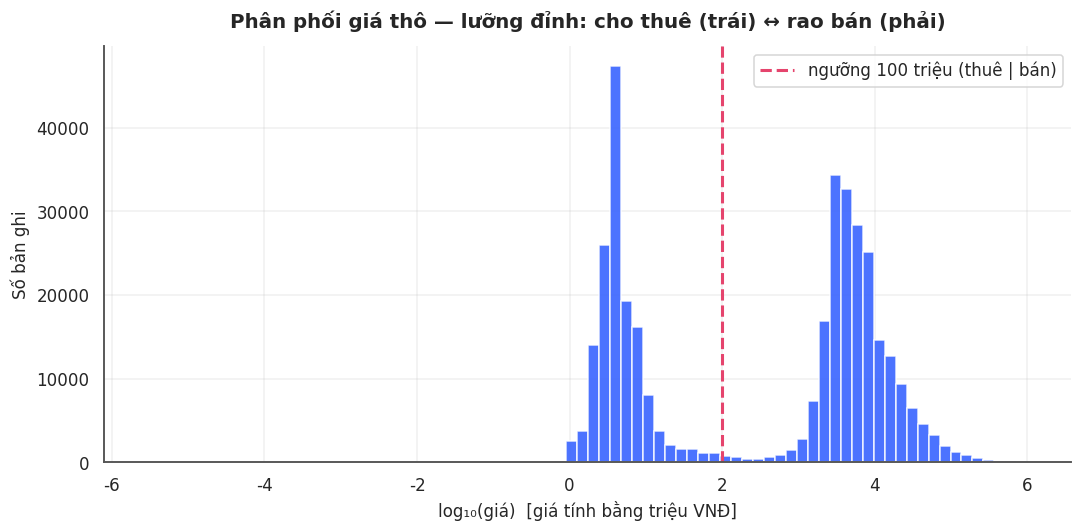

In [5]:
pos = raw.loc[raw["price"] > 0, "price"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log10(pos), bins=80, color=PALETTE[0], alpha=0.85)
ax.axvline(np.log10(100), color=BAD, lw=2, ls="--", label="ngưỡng 100 triệu (thuê | bán)")
ax.set_xlabel("log₁₀(giá)  [giá tính bằng triệu VNĐ]"); ax.set_ylabel("Số bản ghi")
ax.set_title("Phân phối giá thô — lưỡng đỉnh: cho thuê (trái) ↔ rao bán (phải)")
ax.legend(); sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "02_raw_price_bimodal.png"); plt.show()

## 3. Làm sạch giá trị

- **Ép kiểu số** `price`, `area`: chuỗi `"100 m2"`, `"3.300.000đ"`… → số thực (đã ép ở mục 2).
- **Bỏ "Giá thỏa thuận"** (`price == -1`) và mọi `price <= 0`: không có nhãn → vô dụng cho hồi quy.
- **Bỏ `area <= 0`**: diện tích không hợp lệ.


In [6]:
before = len(raw)
df = raw[(raw["price"] > 0) & (raw["area"] > 0)].copy()
print(f"Bỏ price<=0 / area<=0 : {before:,} → {len(df):,}  (loại {before - len(df):,} dòng)")

# Ép cờ tiện ích về {0,1} (đề phòng giá trị lạ) và bedrooms/bathrooms về số
for c in feature_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).clip(0, 1).astype(int)
for c in ["bedrooms", "bathrooms"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Đã chuẩn hóa 12 cờ tiện ích về {0,1}; bedrooms/bathrooms về kiểu số.")

Bỏ price<=0 / area<=0 : 357,851 → 357,664  (loại 187 dòng)
Đã chuẩn hóa 12 cờ tiện ích về {0,1}; bedrooms/bathrooms về kiểu số.


## 4. Tích hợp & tách bài toán: **cho thuê** vs **rao bán**

Bộ thô trộn lẫn tin **cho thuê** (giá triệu/tháng) và tin **rao bán** (giá triệu/căn —
lớn gấp hàng trăm lần). Trộn chung ⇒ so sánh khập khiễng, mô hình giá thuê bị nhiễu nặng.

**Quy tắc tách** (suy ra từ cấu trúc nguồn + ngưỡng giá 100 triệu ở mục 2.1):
- `github_hanoi` là tập **rao bán nhà Hà Nội** → toàn bộ vào **SALE**.
- `chothuenhadattoanvn` chứa **cả hai**: `price > 100` → SALE, còn lại → RENTAL.
- Các nguồn còn lại là sàn **cho thuê** → vào **RENTAL** (vài tin giá cao là nhập sai, giữ lại
  rồi để bước lọc ngoại lệ ở mục 5 xử lý).


In [7]:
SALE_ONLY = {"github_hanoi"}                      # nguồn thuần rao bán
is_sale = df["source"].isin(SALE_ONLY) | (
    (df["source"] == "chothuenhadattoanvn") & (df["price"] > 100))

sale_df   = df[is_sale].copy()
rental_df = df[~is_sale].copy()

print(f"Tổng (đã sạch giá trị) : {len(df):,}")
print(f"  → SALE   (rao bán)   : {len(sale_df):,}")
print(f"  → RENTAL (cho thuê)  : {len(rental_df):,}")
print(f"\nSALE   : giá median = {sale_df['price'].median():,.0f} triệu  (giá BÁN tổng)")
print(f"RENTAL : giá median = {rental_df['price'].median():.1f} triệu/tháng")
print("\nPhân bố nguồn trong RENTAL:")
print(rental_df["source"].value_counts().to_string())

Tổng (đã sạch giá trị) : 357,664
  → SALE   (rao bán)   : 209,709
  → RENTAL (cho thuê)  : 147,955

SALE   : giá median = 5,250 triệu  (giá BÁN tổng)
RENTAL : giá median = 4.0 triệu/tháng

Phân bố nguồn trong RENTAL:
source
chothuephongtro        95574
chothuenhadattoanvn    18837
nhatot                 13175
github_hcm              9662
github_hn               3185
phongtro123             2940
github_housing          1635
lozido                  1329
facebook                 865
github_dn                753


## 5. Lọc ngoại lệ — tập **cho thuê**

Trọng tâm đề tài là **giá thuê**, nên ta làm sạch sâu tập RENTAL. Áp các "rào hợp lý"
(domain bounds) đã thống nhất với khảo sát thị trường:

| Biến | Khoảng giữ lại | Lý do |
|---|---|---|
| `price` | **0.5 – 17** triệu/tháng | dưới 0.5 ≈ nhập sai; trên 17 đã sang phân khúc căn hộ cao cấp / lẫn tin bán |
| `area` | **8 – 180** m² | dưới 8 m² phi thực tế; trên 180 m² là nhà nguyên căn/mặt bằng |
| `bedrooms` | **≤ 6** | trên 6 phòng ngủ là nhà nghỉ / nhập sai |
| `bathrooms` | **≤ 5** | tương tự |


In [8]:
steps = [("Tập RENTAL ban đầu", len(rental_df))]
r = rental_df
r = r[(r["price"] >= 0.5) & (r["price"] <= 17)];  steps.append(("Giá ∈ [0.5, 17]", len(r)))
r = r[(r["area"]  >= 8)   & (r["area"]  <= 180)];  steps.append(("Diện tích ∈ [8, 180]", len(r)))
r = r[r["bedrooms"]  <= 6];                        steps.append(("bedrooms ≤ 6", len(r)))
r = r[r["bathrooms"] <= 5];                        steps.append(("bathrooms ≤ 5", len(r)))
rental_out = r.copy()

for name, cnt in steps:
    print(f"  {name:<26}: {cnt:>8,}")
print(f"\nGiữ lại {len(rental_out):,}/{len(rental_df):,} "
      f"({len(rental_out)/len(rental_df)*100:.1f}%) tập cho thuê sau lọc ngoại lệ.")

  Tập RENTAL ban đầu        :  147,955
  Giá ∈ [0.5, 17]           :  140,278
  Diện tích ∈ [8, 180]      :  136,866
  bedrooms ≤ 6              :  135,914
  bathrooms ≤ 5             :  134,585

Giữ lại 134,585/147,955 (91.0%) tập cho thuê sau lọc ngoại lệ.


### 5.1. Trước / sau lọc — giá & diện tích

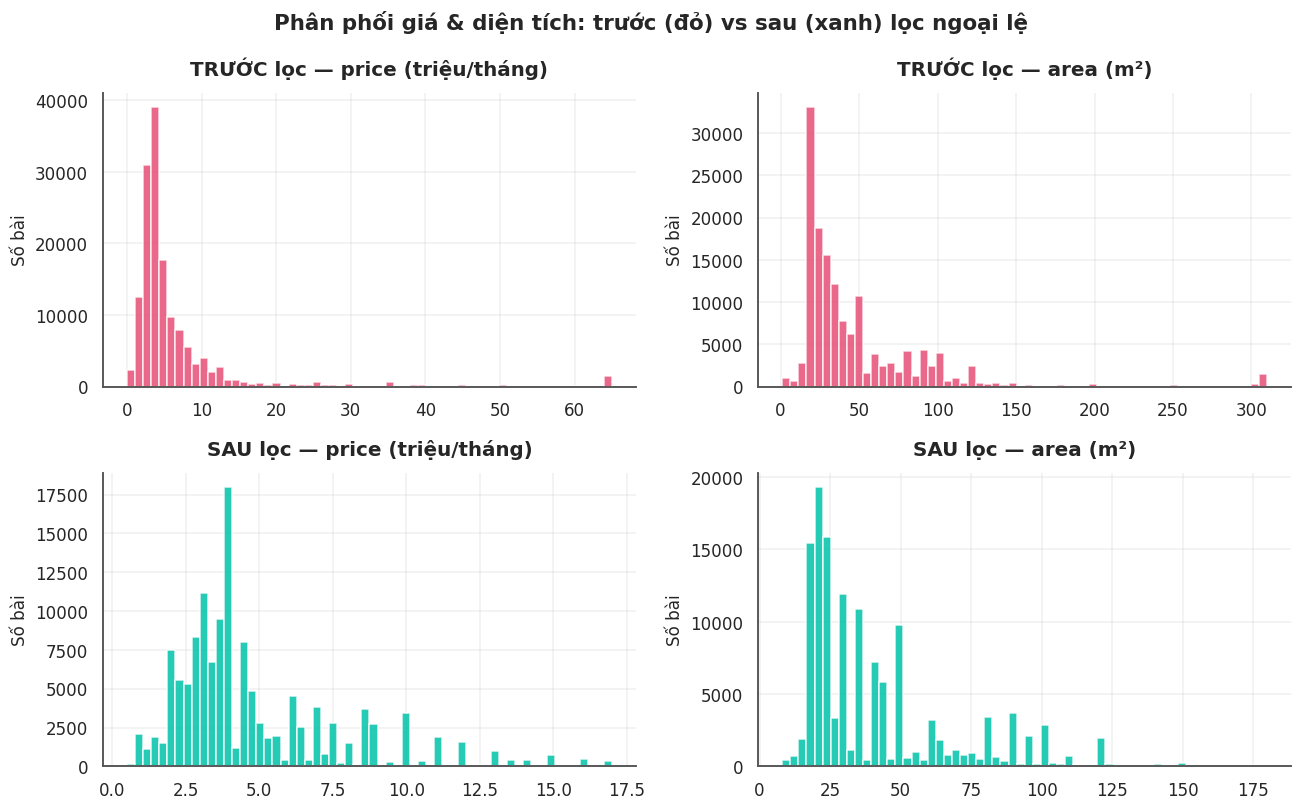

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for j, col, unit in [(0, "price", "triệu/tháng"), (1, "area", "m²")]:
    axes[0, j].hist(rental_df[col].clip(upper=rental_df[col].quantile(0.99)),
                    bins=60, color=BAD, alpha=0.8)
    axes[0, j].set_title(f"TRƯỚC lọc — {col} ({unit})")
    axes[1, j].hist(rental_out[col], bins=60, color=OK, alpha=0.85)
    axes[1, j].set_title(f"SAU lọc — {col} ({unit})")
for ax in axes.ravel():
    ax.set_ylabel("Số bài"); sns.despine(ax=ax)
fig.suptitle("Phân phối giá & diện tích: trước (đỏ) vs sau (xanh) lọc ngoại lệ",
             fontsize=14, fontweight="bold")
plt.tight_layout(); save_mpl(fig, "03_outlier_before_after.png"); plt.show()

## 6. Khử trùng lặp

Cùng một tin có thể được đăng lại / cào nhiều lần. Ta khử trùng theo **tổ hợp khóa**
nhận diện một bài đăng duy nhất: `detail_link` + địa chỉ + giá + diện tích + số phòng.
Giữ bản ghi xuất hiện **đầu tiên**.


In [10]:
KEY = ["detail_link", "full_address", "price", "area", "bedrooms", "bathrooms"]
before = len(rental_out)
rental_clean = rental_out.drop_duplicates(subset=KEY, keep="first").copy()
print(f"Khử trùng lặp: {before:,} → {len(rental_clean):,}  "
      f"(loại {before - len(rental_clean):,} bản trùng)")
print(f"\n✅ Tập cho thuê SẠCH cuối cùng: {len(rental_clean):,} dòng × {rental_clean.shape[1]} cột")

Khử trùng lặp: 134,585 → 133,586  (loại 999 bản trùng)

✅ Tập cho thuê SẠCH cuối cùng: 133,586 dòng × 21 cột


## 7. 🔬 Kiểm toán nguồn gốc 12 cờ tiện ích — phát hiện dữ liệu **bị chế tác**

12 cờ `feature_*` là nhóm đặc trưng *được kỳ vọng quan trọng* cho mô hình. Nhưng khi
**đối chiếu sự xuất hiện của từng cờ theo nguồn** ngay tại Bước 2, ta phát hiện một
**vấn đề toàn vẹn dữ liệu nghiêm trọng**: phần lớn các cờ đã bị **điền ngẫu nhiên lúc gộp nguồn**.

> ⚠️ **Cảnh báo nguồn gốc dữ liệu (kiểm toán Bước 2, 2026-06):** đối chiếu dữ liệu thô từng
> nguồn cho thấy chỉ **5/12 cờ** (máy lạnh, máy giặt, nước nóng, bảo vệ 24/24, hầm để xe)
> có cột gốc thật ở đa số nguồn; **7 cờ còn lại chỉ thật ở `phongtro123`/`lozido` (~3% dữ liệu)**
> và bị *điền ngẫu nhiên* khi gộp nguồn (`chothuenhadattoanvn` + `github_*` không có cờ thật nào).
> Các thống kê mô tả dữ liệu **như-nó-là**; khi vào mô hình (Bước 4) các ô chế tác sẽ được
> **mask NaN theo cơ chế MNAR** và `n_features` (tổng cờ) bị **loại khỏi đặc trưng**.

### Bằng chứng: "dấu vân tay" của việc điền ngẫu nhiên
Nếu một cờ là **thật**, tỷ lệ xuất hiện của nó phải **khác nhau giữa các nguồn** (mỗi
sàn có tệp tin khác nhau). Nếu một cờ bị **điền từ cùng một bộ sinh ngẫu nhiên lúc gộp**,
tỷ lệ của nó sẽ **gần như y hệt** giữa các nguồn không liên quan. Ta đo điều đó bằng
**độ lệch chuẩn của tỷ lệ-xuất-hiện giữa các nguồn lớn**.


In [11]:
# Tỷ lệ xuất hiện mỗi cờ, theo từng nguồn lớn (≥ 1000 bản ghi thô)
big = raw["source"].value_counts()
big = big[big >= 1000].index.tolist()
prev_by_src = (raw[raw["source"].isin(big)]
               .groupby("source")[feature_cols].mean() * 100).round(1)
prev_by_src.columns = [c.replace("feature_", "") for c in prev_by_src.columns]

# Độ lệch chuẩn giữa các nguồn: THẬT → cao (khác nguồn khác tỷ lệ); CHẾ TÁC → ~0
spread = prev_by_src.std(axis=0).sort_values()
print("Độ lệch chuẩn tỷ lệ-xuất-hiện giữa các nguồn (điểm %, càng THẤP càng nghi chế tác):\n")
print(spread.round(2).to_string())

Độ lệch chuẩn tỷ lệ-xuất-hiện giữa các nguồn (điểm %, càng THẤP càng nghi chế tác):

Có tủ lạnh          0.57
Đầy đủ nội thất     2.05
Có kệ bếp           3.54
Có thang máy        3.88
Không chung chủ     4.88
Giờ giấc tự do      5.79
Có gác             10.87
Có máy giặt        15.47
Có máy lạnh        18.22
Có bảo vệ 24/24    20.18
Có nước nóng       21.68
Có hầm để xe       22.38


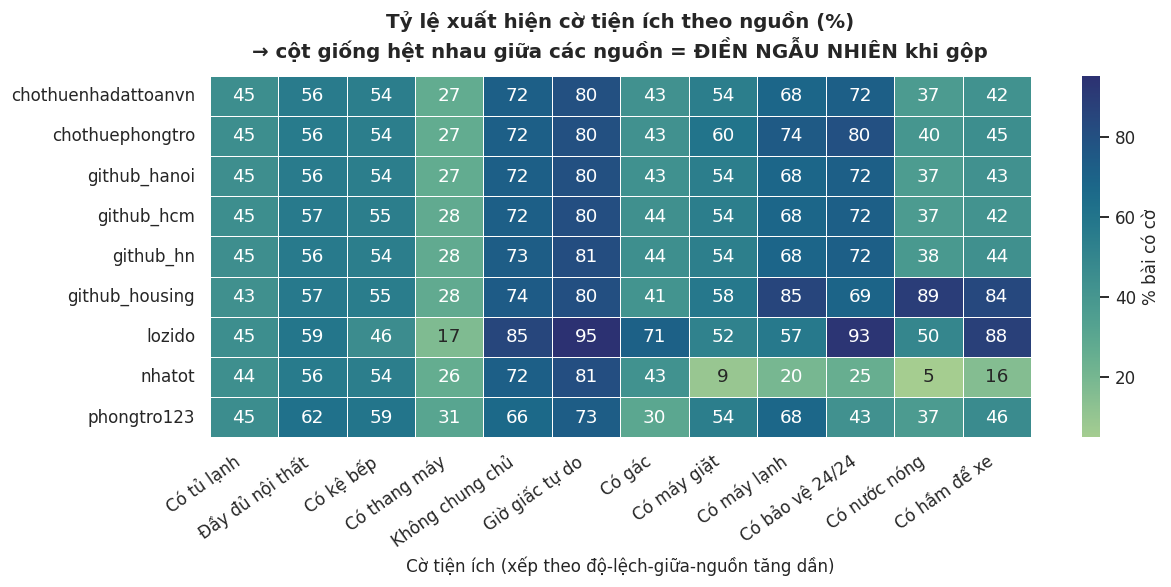

In [12]:
# Trực quan: heatmap tỷ lệ xuất hiện cờ × nguồn — cột "phẳng màu" = bị chế tác
order = spread.index.tolist()                       # cờ nghi chế tác xếp trước
fig, ax = plt.subplots(figsize=(11.5, 5.5))
sns.heatmap(prev_by_src[order], annot=True, fmt=".0f", cmap="crest",
            cbar_kws={"label": "% bài có cờ"}, linewidths=.5, ax=ax)
ax.set_title("Tỷ lệ xuất hiện cờ tiện ích theo nguồn (%)\n"
             "→ cột giống hệt nhau giữa các nguồn = ĐIỀN NGẪU NHIÊN khi gộp")
ax.set_xlabel("Cờ tiện ích (xếp theo độ-lệch-giữa-nguồn tăng dần)"); ax.set_ylabel("")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); save_mpl(fig, "04_amenity_provenance_heatmap.png"); plt.show()

**Đọc heatmap:** với các cờ như *Đầy đủ nội thất, gác, kệ bếp, tủ lạnh, thang máy,
Không chung chủ, Giờ giấc tự do*, ba nguồn **hoàn toàn độc lập** (`chothuenhadattoanvn`,
`github_hcm`, `chothuephongtro`) lại cho **tỷ lệ trùng nhau tới từng %** (≈ 56/43/54/45/27/72/80) —
điều **không thể** xảy ra với dữ liệu thật ⇒ đó là **một bộ giá trị ngẫu nhiên chung** được
ráp vào lúc gộp. Ngược lại 5 cờ thật (máy lạnh, máy giặt, nước nóng, bảo vệ 24/24, hầm để xe)
**dao động mạnh** theo nguồn (vd `nhatot`: máy giặt 9%, nước nóng 5% — tín hiệu thật của sàn đó).

### Hệ quả cho các bước sau (ghi lại để Bước 4 xử lý)


In [13]:
STD5_REAL = ["Có máy lạnh", "Có máy giặt", "Có nước nóng", "Có bảo vệ 24/24", "Có hầm để xe"]
real  = [c for c in feature_cols if c.replace("feature_", "") in STD5_REAL]
forged = [c for c in feature_cols if c not in real]

print("• 5 cờ THẬT ở đa số nguồn  :", [c.replace('feature_','') for c in real])
print("• 7 cờ CHẾ TÁC (điền ngẫu) :", [c.replace('feature_','') for c in forged])
print()
print("Cách xử lý (KHÔNG sửa ở Bước 2 — chỉ lập hồ sơ, để Bước 4 quyết định):")
print("  1) MNAR mask: ô cờ thuộc nguồn không-quan-sát-được → NaN (không khai báo ≠ không có).")
print("     XGBoost/RandomForest xử lý NaN tự nhiên; mô hình tuyến tính impute = tỷ lệ quan sát.")
print("  2) BỎ 'n_features' (tổng 12 cờ) khỏi đặc trưng — vì là tổng của các cờ chế tác.")
print("  3) Ràng buộc đơn điệu +1 cho 12 cờ ở XGBoost — thêm tiện ích không được làm GIẢM giá dự báo.")
print("  4) GIỮ NGUYÊN dữ liệu thô ở Bước 2: ô chế tác vẫn lưu như-nó-là, mask chỉ áp lúc train.")

• 5 cờ THẬT ở đa số nguồn  : ['Có máy lạnh', 'Có máy giặt', 'Có bảo vệ 24/24', 'Có hầm để xe', 'Có nước nóng']
• 7 cờ CHẾ TÁC (điền ngẫu) : ['Đầy đủ nội thất', 'Có gác', 'Có kệ bếp', 'Có tủ lạnh', 'Có thang máy', 'Không chung chủ', 'Giờ giấc tự do']

Cách xử lý (KHÔNG sửa ở Bước 2 — chỉ lập hồ sơ, để Bước 4 quyết định):
  1) MNAR mask: ô cờ thuộc nguồn không-quan-sát-được → NaN (không khai báo ≠ không có).
     XGBoost/RandomForest xử lý NaN tự nhiên; mô hình tuyến tính impute = tỷ lệ quan sát.
  2) BỎ 'n_features' (tổng 12 cờ) khỏi đặc trưng — vì là tổng của các cờ chế tác.
  3) Ràng buộc đơn điệu +1 cho 12 cờ ở XGBoost — thêm tiện ích không được làm GIẢM giá dự báo.
  4) GIỮ NGUYÊN dữ liệu thô ở Bước 2: ô chế tác vẫn lưu như-nó-là, mask chỉ áp lúc train.


## 8. Xem trước Feature Engineering — tách **khu vực** từ địa chỉ

Đề tài là "phân tích **theo khu vực**" nên `city`/`district` là đặc trưng cốt lõi. Bộ dữ
liệu **không** có sẵn hai cột này — phải **tách từ `full_address`** bằng regex. Logic này
là *single source of truth* dùng chung train (Bước 4) & serve (app Bước 6); ở đây ta **xem
trước** để kiểm chứng chất lượng tách (không lưu thành cột cố định trong file Bước 2).


In [14]:
PROVINCES = ["Hà Nội", "Hồ Chí Minh", "Đà Nẵng", "Bình Dương", "Hưng Yên",
             "Hải Phòng", "Quảng Ninh", "Khánh Hòa", "Đồng Nai", "Cần Thơ",
             "Bắc Ninh", "Hải Dương", "Nghệ An", "Thừa Thiên Huế", "Huế",
             "Bà Rịa", "Vũng Tàu", "Lâm Đồng", "Thanh Hóa", "Quảng Nam"]
_dist_re = re.compile(r"^(Quận|Huyện|Thị xã|Thành phố|TP)\s", re.IGNORECASE)

def parse_address(addr):
    parts = [p.strip() for p in str(addr).split(",") if p.strip()]
    city = None
    for p in reversed(parts):
        for prov in PROVINCES:
            if prov.lower() in p.lower():
                city = prov; break
        if city: break
    if city is None and parts:
        city = parts[-1]
    district = next((p for p in parts if _dist_re.match(p)), None)
    return city, district

_p = rental_clean["full_address"].apply(parse_address)
_city     = _p.map(lambda x: x[0])
_district = _p.map(lambda x: x[1])

print("Top 5 thành phố tách được :", _city.value_counts().head(5).to_dict())
print("Số quận/huyện riêng biệt  :", _district.nunique())
print(f"Thiếu district            : {_district.isna().sum():,}/{len(rental_clean):,} "
      f"({_district.isna().mean()*100:.1f}%)")
print("\n(city/district được sinh lại ở Bước 3/4 từ chính full_address — không khóa cứng vào CSV.)")

Top 5 thành phố tách được : {'Hà Nội': 117574, 'Hồ Chí Minh': 11559, 'Đà Nẵng': 1411, 'Bình Dương': 358, 'Hưng Yên': 264}
Số quận/huyện riêng biệt  : 352
Thiếu district            : 2,938/133,586 (2.2%)

(city/district được sinh lại ở Bước 3/4 từ chính full_address — không khóa cứng vào CSV.)


## 9. Load — Lưu sản phẩm Bước 2 & tổng kết ETL

Ghi ba tập vào `v2/data/processed/` (v2-local, **không đụng** file canonical đã audit):

| File | Nội dung | Dùng cho |
|---|---|---|
| `rental_data.csv` | tập cho thuê **trước** lọc ngoại lệ | tham chiếu / kiểm tra |
| `sale_data.csv` | tập rao bán (tách riêng) | ngoài phạm vi mô hình giá thuê |
| `rental_data_clean.csv` | **tập cho thuê đã làm sạch** | ⭐ đầu vào EDA (B3) & mô hình (B4) |


In [15]:
rental_df.to_csv(OUT / "rental_data.csv", index=False)
sale_df.to_csv(OUT / "sale_data.csv", index=False)
rental_clean.to_csv(OUT / "rental_data_clean.csv", index=False)

for f in ["rental_data.csv", "sale_data.csv", "rental_data_clean.csv"]:
    p = OUT / f
    print(f"  ✅ {f:<24} {len(pd.read_csv(p, low_memory=False)):>8,} dòng  →  {p}")

  ✅ rental_data.csv           147,955 dòng  →  /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/data/processed/rental_data.csv


  ✅ sale_data.csv             209,709 dòng  →  /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/data/processed/sale_data.csv


  ✅ rental_data_clean.csv     133,586 dòng  →  /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/data/processed/rental_data_clean.csv


=== PHỄU LÀM SẠCH (data cleaning funnel) ===
               Bước xử lý  Số dòng còn lại  % so với thô
             Thô (Bước 1)           357851         100.0
      Bỏ price≤0 / area≤0           357664          99.9
  Tách RENTAL (loại SALE)           147955          41.3
Lọc ngoại lệ giá/DT/phòng           134585          37.6
     Khử trùng lặp → SẠCH           133586          37.3


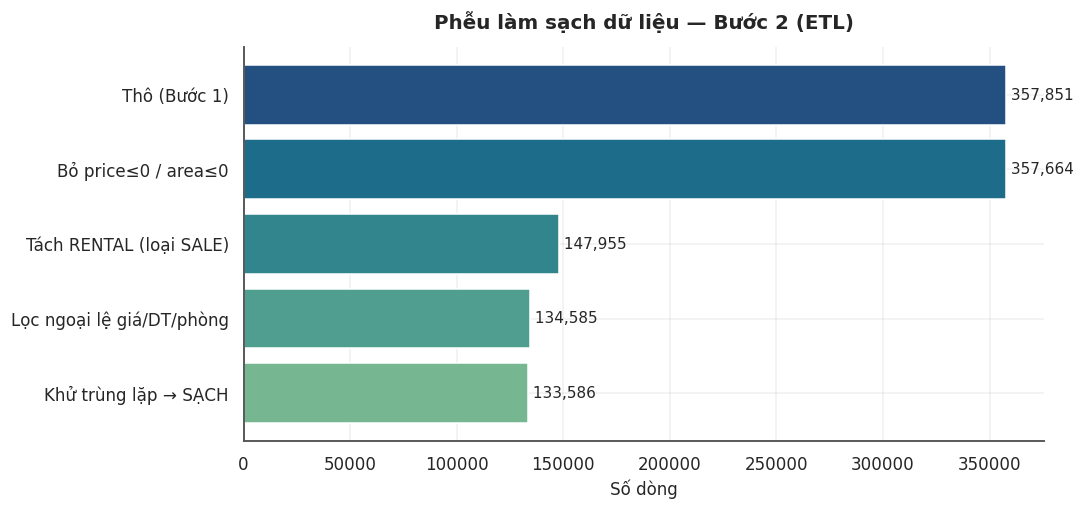

In [16]:
summary = pd.DataFrame([
    ("Thô (Bước 1)",              len(raw)),
    ("Bỏ price≤0 / area≤0",       len(df)),
    ("Tách RENTAL (loại SALE)",   len(rental_df)),
    ("Lọc ngoại lệ giá/DT/phòng", len(rental_out)),
    ("Khử trùng lặp → SẠCH",      len(rental_clean)),
], columns=["Bước xử lý", "Số dòng còn lại"])
summary["% so với thô"] = (summary["Số dòng còn lại"] / len(raw) * 100).round(1)
print("=== PHỄU LÀM SẠCH (data cleaning funnel) ===")
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(summary["Bước xử lý"][::-1], summary["Số dòng còn lại"][::-1],
               color=sns.color_palette("crest", len(summary)))
for b, v in zip(bars, summary["Số dòng còn lại"][::-1]):
    ax.text(v, b.get_y() + b.get_height()/2, f" {v:,}", va="center", fontsize=10)
ax.set_xlabel("Số dòng"); ax.set_title("Phễu làm sạch dữ liệu — Bước 2 (ETL)")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "05_cleaning_funnel.png"); plt.show()

## 10. Kết luận Bước 2

1. **Tích hợp:** 11 nguồn gộp về **một lược đồ chung** (`title/price/area/.../source` + 12 cờ tiện ích).
2. **Làm sạch giá trị:** ép kiểu số, loại "Giá thỏa thuận" (`price=-1`) & giá/diện tích phi lý.
3. **Tách bài toán:** phát hiện dữ liệu **lưỡng đỉnh** → tách **cho thuê** khỏi **rao bán**
   (ngưỡng giá 100 triệu + nguồn `github_hanoi`), tránh trộn hai loại giá khác đơn vị.
4. **Lọc ngoại lệ + khử trùng:** tập cho thuê sạch còn **~133K bản ghi** trong rào hợp lý
   (giá 0.5–17 triệu, diện tích 8–180 m²).
5. 🔬 **Khám phá quan trọng (insight):** kiểm toán nguồn gốc phát hiện **7/12 cờ tiện ích bị
   điền ngẫu nhiên** khi gộp nguồn — bằng chứng là tỷ lệ xuất hiện *trùng khít* giữa các nguồn
   độc lập. Đây là **rủi ro toàn vẹn dữ liệu** quyết định cách Bước 4 xử lý (mask MNAR, bỏ
   `n_features`, ràng buộc đơn điệu) — đúng tinh thần "Garbage In, Garbage Out".

**Sản phẩm bàn giao:** `v2/data/processed/rental_data_clean.csv` → sẵn sàng cho **Bước 3 (EDA)**.
